# Telecom Customer Churn — Data Cleaning (Final Version)

In this notebook we clean the data step by step and make it ready for the churn prediction model.

Steps we will do:
1. Load the data
2. Handle missing values
3. Check duplicates and useless columns
4. Check category columns
5. Check the target column (Churn)
6. Drop the columns we don't need (with proof why)
7. Save the cleaned data

In [1]:
# ===============================
# Data Handling
# ===============================
import numpy as np
import pandas as pd

# ===============================
# Visualization
# ===============================
import matplotlib.pyplot as plt
import seaborn as sns

## Step 1 — Load the Data

In [3]:
# if you run this on your laptop, change the path to where the csv file is kept
df = pd.read_csv('/kaggle/input/datasets/shreyy45/telecom-dataset/telecom_customer_churn_synthetic.csv')

print("Rows and Columns:", df.shape)
df.head()

Rows and Columns: (300000, 67)


,CustomerID,Gender,Age,MaritalStatus,Dependents,Occupation,IncomeGroup,Education,Region,CityType,...,PromotionAcceptance,CLV,ARPU,Recency_Days,Frequency_Score,MonetaryScore,EngagementScore,RiskScore,LoyaltyScore,Churn
0,ATT-100000,Female,55,Divorced,0,Salaried,NaN,Diploma,South,Urban,...,Yes,766.76,59.05,13,6.17,5,49.5,32.0,0.0,No
1,VZW-100001,Female,31,Single,0,Salaried,Low,High School,South,Suburban,...,Yes,878.06,29.34,11,10.00,2,59.7,0.0,71.6,No
2,VOD-100002,Male,55,Single,0,Salaried,Lower-Mid,Bachelor,North,Urban,...,No,767.90,50.94,23,5.67,4,46.2,38.5,28.3,No
3,VZW-100003,Male,28,Divorced,0,Salaried,Upper-Mid,Diploma,North,Urban,...,No,889.20,50.26,20,4.83,4,51.1,17.0,1.1,No
4,VZW-100004,Male,39,Single,1,Salaried,Lower-Mid,Bachelor,Central,Urban,...,Yes,519.01,36.70,20,5.83,2,47.6,28.1,0.0,No


## Step 2 — Missing Values

First we check which columns have missing values and how much % is missing.

In [4]:
# Count missing values
missing_values = df.isnull().sum()

# Percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create a summary table
missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

# Show only columns with missing values
missing_df = missing_df[missing_df["Missing Values"] > 0]

missing_df.sort_values(by="Missing Values", ascending=False)

,Missing Values,Percentage
CustomerSatisfactionScore,15000,5.0
IncomeGroup,12000,4.0
AvgInternetSpeedMbps,9000,3.0
Education,7500,2.5
OutstandingBalance,6000,2.0


Only 5 columns have missing values and all are small (2% to 5%). So we don't need to delete any rows, we can just fill them.

- Numeric columns → fill with **median** (median is safe because very big or very small values do not affect it)
- Category columns → fill with **mode** (the most repeated value)

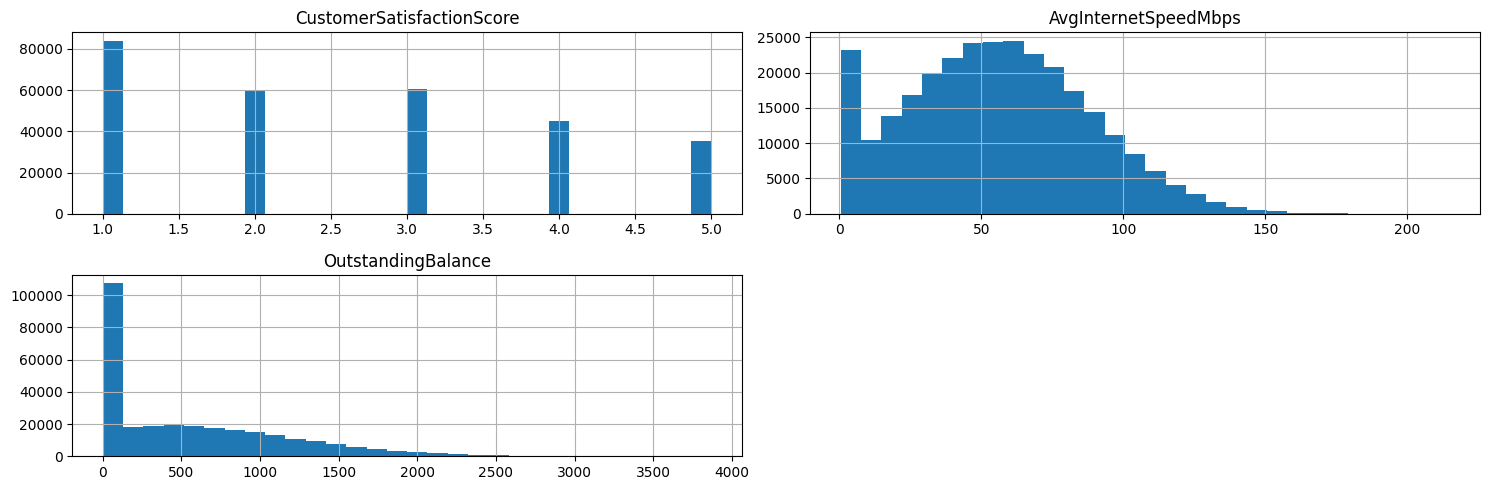

In [5]:
# first see the shape of the numeric columns which have missing values
numerical_missing = [
    "CustomerSatisfactionScore",
    "AvgInternetSpeedMbps",
    "OutstandingBalance"
]

df[numerical_missing].hist(figsize=(15, 5), bins=30)

plt.tight_layout()
plt.show()

In [7]:
# fill numeric columns with median
numerical_fill = {
    "CustomerSatisfactionScore": df["CustomerSatisfactionScore"].median(),
    "AvgInternetSpeedMbps": df["AvgInternetSpeedMbps"].median(),
    "OutstandingBalance": df["OutstandingBalance"].median()
}

df.fillna(value=numerical_fill, inplace=True)

In [8]:
# fill category columns with mode (most repeated value)
categorical_fill = {
    "IncomeGroup": df["IncomeGroup"].mode()[0],
    "Education": df["Education"].mode()[0]
}

df.fillna(value=categorical_fill, inplace=True)

# check again - now total missing should be 0
print("Total missing values left:", df.isnull().sum().sum())

Total missing values left: 0


## Step 3 — Duplicates and Useless Columns

In [9]:
# check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# check columns which have only one same value in all rows (useless columns)
constant_columns = []

for col in df.columns:
    if df[col].nunique() == 1:
        constant_columns.append(col)

print("Constant Columns:", constant_columns)

Duplicate rows: 0
Constant Columns: []


No duplicate rows and no constant columns. Good.

## Step 4 — Check Category Columns

We check the unique values of every category column to see if there is any spelling mistake or extra space (like "Yes " and "Yes").

In [10]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    if col == "CustomerID":
        continue  # this is just an id, no need to check its values

    print(f"\n{'='*50}")
    print(f"{col}")
    print(df[col].unique())


Gender
['Female' 'Male' 'Other']

MaritalStatus
['Divorced' 'Single' 'Married']

Occupation
['Salaried' 'Business' 'Student' 'Retired' 'Homemaker' 'Unemployed']

IncomeGroup
['Lower-Mid' 'Low' 'Upper-Mid' 'High']

Education
['Diploma' 'High School' 'Bachelor' 'Master' 'PhD']

Region
['South' 'North' 'Central' 'West' 'East']

CityType
['Urban' 'Suburban' 'Rural']

ContractType
['Month-to-Month' 'Two Year' 'One Year']

PlanType
['Prepaid' 'Postpaid']

InternetType
['5G' 'DSL' 'Fiber' '4G' 'No Internet']

VoicePlan
['Yes' 'No']

SMSPlan
['No' 'Yes']

OTTSubscription
['No' 'Yes']

InternationalCalling
['Yes' 'No']

FamilyPlan
['No' 'Yes']

PaymentMethod
['Cash' 'UPI' 'Credit Card' 'Debit Card' 'Net Banking' 'E-Wallet']

AutoPay
['No' 'Yes']

LoyaltyProgramMember
['No' 'Yes']

PromotionAcceptance
['Yes' 'No']

Churn
['No' 'Yes']


All category values are clean. No spelling mistake and no extra space.

## Step 5 — Check the Target Column (Churn)

We check how many customers left (Yes) and how many stayed (No).

In [11]:
# Count each class
print(df["Churn"].value_counts())

# Percentage
print("\nPercentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     220621
Yes     79379
Name: count, dtype: int64

Percentage:
Churn
No     73.540333
Yes    26.459667
Name: proportion, dtype: float64


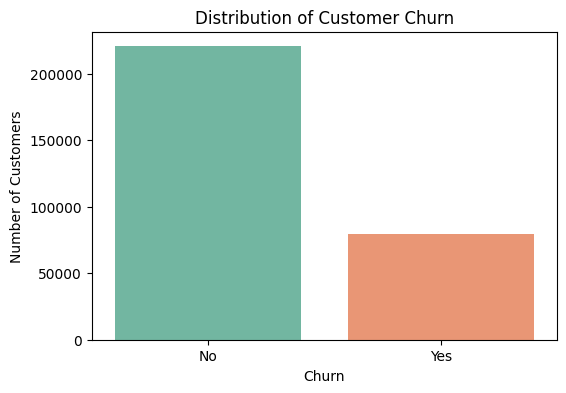

In [13]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Around 73.5% customers stayed and 26.5% left. So the data is imbalanced. We should remember this later — when we split the data for the model, we should use `stratify` so both train and test get the same ratio.

## Step 6 — Dropping Columns (Main Part)

We have 67 columns but we don't need all of them. We will drop 3 types of columns:

**Type 1 — ID column**

| Column | Reason to drop |
|---|---|
| `CustomerID` | It is just a serial number. It tells nothing about the customer. |

**Type 2 — Copy / repeated columns** (two columns giving the same info, so we keep one and drop the other)

| Column | Reason to drop |
|---|---|
| `AvgMonthlyBill` | Exact copy of `MonthlyCharges` (correlation = 1.00) |
| `ARPU` | Almost same as `MonthlyCharges` (correlation = 0.99) |
| `TotalCharges` | It is just `Tenure_Months × MonthlyCharges`. We already have both columns. |

**Type 3 — Ready-made score columns** (the company already calculated these scores using the other columns, so they don't give new info — and one of them is basically the answer itself)

| Column | Reason to drop |
|---|---|
| `RiskScore` | This is the company's own churn risk score. It almost tells the answer. If we keep it, our model will just copy it and we will not learn which real things (complaints, network, bills) cause churn. Also, this score will not be there for a new customer in real life. |
| `CLV` | Strongly related to RiskScore, so the answer is hidden inside it too |
| `LoyaltyScore` | Made from Tenure + RewardPoints |
| `EngagementScore` | Made from app sessions and active days |
| `Frequency_Score` | Made from ActiveDaysPerMonth |
| `MonetaryScore` | Made from MonthlyCharges |
| `Recency_Days` | Just the opposite of ActiveDaysPerMonth |

First let us see the proof, then we drop them.

In [14]:
# PROOF 1: copy columns
# correlation near 1 means both columns give the same info
print("MonthlyCharges vs AvgMonthlyBill        :", round(df["MonthlyCharges"].corr(df["AvgMonthlyBill"]), 4))
print("MonthlyCharges vs ARPU                  :", round(df["MonthlyCharges"].corr(df["ARPU"]), 4))
print("TotalCharges vs Tenure x MonthlyCharges :", round(df["TotalCharges"].corr(df["Tenure_Months"] * df["MonthlyCharges"]), 4))

MonthlyCharges vs AvgMonthlyBill        : 1.0
MonthlyCharges vs ARPU                  : 0.9897
TotalCharges vs Tenure x MonthlyCharges : 0.9975


In [15]:
# PROOF 2: score columns are made from other columns which we already have
print("Frequency_Score vs ActiveDaysPerMonth :", round(df["Frequency_Score"].corr(df["ActiveDaysPerMonth"]), 4))
print("MonetaryScore vs MonthlyCharges       :", round(df["MonetaryScore"].corr(df["MonthlyCharges"]), 4))
print("EngagementScore vs AppSessions        :", round(df["EngagementScore"].corr(df["MobileAppSessionsPerMonth"]), 4))
print("Recency_Days vs ActiveDaysPerMonth    :", round(df["Recency_Days"].corr(df["ActiveDaysPerMonth"]), 4))
print("CLV vs RiskScore                      :", round(df["CLV"].corr(df["RiskScore"]), 4))

Frequency_Score vs ActiveDaysPerMonth : 0.9432
MonetaryScore vs MonthlyCharges       : 0.9423
EngagementScore vs AppSessions        : 0.8985
Recency_Days vs ActiveDaysPerMonth    : -0.8984
CLV vs RiskScore                      : -0.725


In [16]:
# PROOF 3: RiskScore alone almost tells who will churn (cheating column)
low_risk = df[df["RiskScore"] <= 15]
high_risk = df[df["RiskScore"] >= 50]

print("Churn % when RiskScore is LOW  :", round((low_risk["Churn"] == "Yes").mean() * 100, 1), "%")
print("Churn % when RiskScore is HIGH :", round((high_risk["Churn"] == "Yes").mean() * 100, 1), "%")

Churn % when RiskScore is LOW  : 6.9 %
Churn % when RiskScore is HIGH : 65.7 %


In [26]:
# now drop all these columns
columns_to_drop = [
    # id column
    "CustomerID",

    # copy / repeated columns
    "AvgMonthlyBill",
    "ARPU",
    "TotalCharges",

    # ready-made score columns
    "RiskScore",
    "CLV",
    "LoyaltyScore",
    "EngagementScore",
    "Frequency_Score",
    "MonetaryScore",
    "Recency_Days"
]


df = df.drop(columns=columns_to_drop, errors="ignore")

print("Shape after dropping:", df.shape)

Shape after dropping: (300000, 56)


## Step 7 — Save the Cleaned Data

In [28]:
# save the cleaned data as a new csv file
df.to_csv("telecom_churn_cleaned.csv", index=False)

print("Cleaned data saved!")
print("Final shape:", df.shape)
df.head()

Cleaned data saved!
Final shape: (300000, 56)


,Gender,Age,MaritalStatus,Dependents,Occupation,IncomeGroup,Education,Region,CityType,ContractType,...,AvgInternetSpeedMbps,CoverageRating,MobileAppSessionsPerMonth,WebsiteLoginFrequency,LoyaltyProgramMember,RewardPoints,ReferralCount,MarketingEmailOpenRatePct,PromotionAcceptance,Churn
0,Female,55,Divorced,0,Salaried,Lower-Mid,Diploma,South,Urban,Month-to-Month,...,39.9,1,11,9,No,23.0,1,22.4,Yes,No
1,Female,31,Single,0,Salaried,Low,High School,South,Suburban,Two Year,...,105.1,5,10,10,Yes,750.0,1,20.6,Yes,No
2,Male,55,Single,0,Salaried,Lower-Mid,Bachelor,North,Urban,Month-to-Month,...,41.7,2,7,5,Yes,971.0,0,25.0,No,No
3,Male,28,Divorced,0,Salaried,Upper-Mid,Diploma,North,Urban,One Year,...,30.7,1,18,6,No,39.0,0,29.2,No,No
4,Male,39,Single,1,Salaried,Lower-Mid,Bachelor,Central,Urban,Two Year,...,55.9,3,13,8,No,18.0,0,16.5,Yes,No


## Summary

What we did in this notebook:
1. Loaded the data → 300000 rows and 67 columns
2. Filled missing values → median for numeric, mode for category
3. Checked duplicates → 0 found
4. Checked category columns → all clean
5. Checked Churn → 73.5% No, 26.5% Yes (imbalanced)
6. Dropped 11 columns (1 id + 3 copy columns + 7 ready-made scores) → 56 columns left
7. Saved the cleaned file as `telecom_churn_cleaned.csv`

Next steps (for the next notebook):
- Convert category columns to numbers (Label Encoding / One-Hot Encoding)
- Split the data into train and test (use `stratify` because data is imbalanced)
- Train the model